# Ejercicio pandas estadística
Para este ejercicio se ha utilizado [un dataset de un concurso de kaggle](https://www.kaggle.com/nickhould/craft-cans), cuyo reto consiste en predecir el tipo de cerveza en función de sus características (nivel de alcohol, amargura, tamaño...).

# Ejercicio 1
Importa las librerias que consideres

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<span style="color:yellow">En programación, Python por sí solo viene con funciones básicas. Para hacer análisis de datos avanzados, necesitamos cargar "cajas de herramientas" especializadas llamadas librerías. Al escribir </span>`import pandas as pd`<span style="color:yellow">, le estamos diciendo al programa que traiga la librería Pandas y le ponga un apodo corto (</span>`pd`<span style="color:yellow">) para no tener que escribir su nombre entero cada vez. Hacemos lo mismo con </span>`numpy`<span style="color:yellow"> (para operaciones matemáticas), </span>`matplotlib.pyplot`<span style="color:yellow"> y </span>`seaborn`<span style="color:yellow"> (para dibujar gráficos).</span>

## Ejercicio 2
1. Importa el dataset "datasets_beer.csv"
2. Imprime por pantalla los primeros registros.
3. ¿Cuáles son sus columnas?
4. ¿Qué dimensiones tiene el DataFrame?

In [24]:
# Cargar el archivo CSV
df_beer = pd.read_csv("data/datasets_beers.csv")

# Mostrar los 5 primeros registros
display("--- Primeros registros ---")
display(df_beer.head())

# Mostrar los nombres de las columnas
display("\n--- Columnas del DataFrame ---")
display(df_beer.columns)

# Mostrar las dimensiones (filas, columnas)
display("\n--- Dimensiones ---")
display(df_beer.shape)

'--- Primeros registros ---'

,Unnamed: 0,abv,ibu,id,name,style,brewery_id,ounces
0,0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0


'\n--- Columnas del DataFrame ---'

Index(['Unnamed: 0', 'abv', 'ibu', 'id', 'name', 'style', 'brewery_id',
       'ounces'],
      dtype='str')

'\n--- Dimensiones ---'

(2410, 8)

<span style="color:yellow">Para abrir un archivo de datos utilizamos la función </span>`pd.read_csv()`<span style="color:yellow">, que lee el documento y lo convierte en una tabla estructurada (un DataFrame) llamada </span>`df_beer`<span style="color:yellow">. Con </span>`df_beer.head()`<span style="color:yellow"> le pedimos que nos enseñe únicamente las primeras 5 filas para comprobar visualmente que la información se ha cargado bien. Con </span>`df_beer.columns`<span style="color:yellow"> obtenemos la lista con los nombres de todos los encabezados. Finalmente, </span>`df_beer.shape`<span style="color:yellow"> nos devuelve un par de números que representan el tamaño del "mapa": el primer número es el total de filas (registros de cervezas) y el segundo es el total de columnas (características medidas).</span>

## Ejercicio 3
[Elimina la columna "Unnamed: 0"](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html)

In [25]:
# Eliminar la columna redundantemente generada por el índice previo
df_beer = df_beer.drop(columns=['Unnamed: 0'])

<span style="color:yellow">Al guardar tablas en archivos CSV, a menudo se crea una columna de numeración sin nombre que la librería lee como </span>`Unnamed: 0`<span style="color:yellow">. Como esta columna no aporta ningún valor al análisis, usamos la función </span>`drop()`<span style="color:yellow"> especificando en el argumento </span>`columns=['Unnamed: 0']`<span style="color:yellow"> qué columna queremos borrar. Al escribir </span>`df_beer = `<span style="color:yellow"> al principio, estamos sobreescribiendo nuestra variable para guardar la tabla limpia y sin esa columna inservible.</span>

## Ejercicio 4
¿Cuántas filas y columnas tiene el dataset?

In [26]:
filas, columnas = df_beer.shape
display(f"El dataset contiene {filas} filas y {columnas} columnas.")

'El dataset contiene 2410 filas y 7 columnas.'

<span style="color:yellow">La propiedad </span>`shape`<span style="color:yellow"> guarda dos datos ordenados: el número de filas y el de columnas. En Python podemos "desempaquetar" esos dos datos en dos variables separadas llamadas </span>`filas`<span style="color:yellow"> y </span>`columnas`<span style="color:yellow">. Las filas representan cada uno de los registros individuales (cada cerveza de la muestra) y las columnas son las variables recopiladas sobre ellas (como su graduación de alcohol o su volumen en onzas).</span>

## Ejercicio 5
¿De qué tipo son los datos?

In [27]:
df_beer.dtypes

abv           float64
ibu           float64
id              int64
name              str
style             str
brewery_id      int64
ounces        float64
dtype: object

<span style="color:yellow">Cada columna de una tabla debe almacenar la información con una estructura matemática concreta. La propiedad </span>`dtypes`<span style="color:yellow"> nos muestra el tipo de dato de cada columna: </span>`int64`<span style="color:yellow"> significa números enteros (sin decimales), </span>`float64`<span style="color:yellow"> indica números con decimales (como la graduación alcohólica) y </span>`object`<span style="color:yellow"> representa cadenas de texto (como el nombre de la cerveza o su estilo). Esta comprobación es crucial porque solo se pueden calcular medias o desviaciones típicas sobre columnas numéricas.</span>

## Ejercicio 6
Obtén en un nuevo DataFrame un resumen con las principales estadísticas de las columnas numéricas: mean, max, count, cuartiles...

In [28]:
df_beer.describe()

,abv,ibu,id,brewery_id,ounces
count,2348.000000,1405.000000,2410.000000,2410.000000,2410.000000
mean,0.059773,42.713167,1431.113278,231.749793,13.592241
std,0.013542,25.954066,752.459975,157.685604,2.352204
min,0.001000,4.000000,1.000000,0.000000,8.400000
25%,0.050000,21.000000,808.250000,93.000000,12.000000
50%,0.056000,35.000000,1453.500000,205.000000,12.000000
75%,0.067000,64.000000,2075.750000,366.000000,16.000000
max,0.128000,138.000000,2692.000000,557.000000,32.000000


<span style="color:yellow">La función </span>`describe()`<span style="color:yellow"> es el "escáner médico" de cualquier dataset. Analiza automáticamente todas las columnas con números y nos devuelve una tabla informativa con los siguientes indicadores: </span>`count`<span style="color:yellow"> (cuántos datos válidos existen), </span>`mean`<span style="color:yellow"> (el valor medio), </span>`std`<span style="color:yellow"> (la desviación típica o cuánto se alejan los datos de la media), </span>`min`<span style="color:yellow"> y </span>`max`<span style="color:yellow"> (los valores extremos), y los porcentajes </span>`25%`<span style="color:yellow">, </span>`50%`<span style="color:yellow"> y </span>`75%`<span style="color:yellow"> (llamados cuartiles, que dividen los datos en cuatro partes iguales; el 50% equivale a la mediana).</span>

## Ejercicio 7
¿Cuántas birras hay de cada estilo en este dataset? [Investiga en la documentación de Series](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.html) si puedes hacer un conteo de valores.

In [29]:
df_beer['style'].value_counts()

style
American IPA                      424
American Pale Ale (APA)           245
American Amber / Red Ale          133
American Blonde Ale               108
American Double / Imperial IPA    105
                                 ... 
American Malt Liquor                1
Grisette                            1
Flanders Oud Bruin                  1
Braggot                             1
Low Alcohol Beer                    1
Name: count, Length: 99, dtype: int64

<span style="color:yellow">Cuando seleccionamos una sola columna de un DataFrame escribiendo </span>`df_beer['style']`<span style="color:yellow">, obtenemos una estructura llamada </span>`Series`<span style="color:yellow">. Las Series tienen un método muy potente llamado </span>`value_counts()`<span style="color:yellow">. Lo que hace esta función es agrupar internamente todas las cervezas que comparten el mismo estilo (por ejemplo, todas las 'American IPA'), contar cuántas hay de cada uno y devolvernos una lista ordenada desde el estilo más común hasta el más raro.</span>

## Ejercicio 8
1. Imprime por pantalla los registros desde el décimo hasta el vigésimo
2. De esos registros, imprime por pantalla desde la columna `name` a `ounces`, ambas incluidas
3. Quédate con las columnas `abv`, `ibu` y `ounces`, y además quédate sólo con los registros 10 al 20.
4. Convierte el resultado del apartado 3 en un array de `numpy`

In [30]:
# 1. Registros desde el décimo hasta el vigésimo (posiciones 10 a 20 inclusive)
apartado_1 = df_beer.iloc[10:21]

# 2. De esos registros, columnas desde 'name' a 'ounces' (ambas incluidas)
apartado_2 = df_beer.loc[10:20, 'name':'ounces']

# 3. Columnas 'abv', 'ibu' y 'ounces', para los registros 10 al 20
apartado_3 = df_beer.loc[10:20, ['abv', 'ibu', 'ounces']]

# 4. Convertir el resultado del apartado 3 en un array de numpy
array_numpy = apartado_3.to_numpy()

display("--- Apartado 3 (DataFrame) ---")
display(apartado_3)
display("\n--- Apartado 4 (Matriz NumPy) ---")
display(array_numpy)

'--- Apartado 3 (DataFrame) ---'

,abv,ibu,ounces
10,0.072,NaN,12.0
11,0.073,NaN,12.0
12,0.069,NaN,12.0
13,0.085,NaN,12.0
14,0.061,60.0,12.0
15,0.060,NaN,12.0
16,0.060,NaN,12.0
17,0.060,NaN,12.0
18,0.060,NaN,12.0
19,0.082,NaN,12.0


'\n--- Apartado 4 (Matriz NumPy) ---'

array([[ 0.072,    nan, 12.   ],
       [ 0.073,    nan, 12.   ],
       [ 0.069,    nan, 12.   ],
       [ 0.085,    nan, 12.   ],
       [ 0.061, 60.   , 12.   ],
       [ 0.06 ,    nan, 12.   ],
       [ 0.06 ,    nan, 12.   ],
       [ 0.06 ,    nan, 12.   ],
       [ 0.06 ,    nan, 12.   ],
       [ 0.082,    nan, 12.   ],
       [ 0.082,    nan, 12.   ]])

<span style="color:yellow">En Pandas hay dos formas principales de recortar una tabla. Con </span>`iloc`<span style="color:yellow"> usamos coordenadas puramente numéricas (como jugar al hundir la flota). Escribir </span>`iloc[10:21]`<span style="color:yellow"> extrae desde la fila en posición 10 hasta la 20. Por otro lado, </span>`loc`<span style="color:yellow"> permite seleccionar filas y columnas mediante sus nombres o etiquetas. Al escribir </span>`loc[10:20, 'name':'ounces']`<span style="color:yellow"> le pedimos las filas numeradas del 10 al 20 y todas las columnas comprendidas entre 'name' y 'ounces'. Finalmente, con </span>`to_numpy()`<span style="color:yellow"> quitamos los encabezados de la tabla de Pandas y nos quedamos únicamente con los números puros organizados en una matriz rectangular de </span>`numpy`<span style="color:yellow">.</span>

## Ejercicio 9
¿Cuántas onzas pesan todas las birras del dataset?

In [31]:
total_onzas = df_beer['ounces'].sum()
display(f"El peso/volumen total de todas las cervezas es de {total_onzas} onzas.")

'El peso/volumen total de todas las cervezas es de 32757.3 onzas.'

<span style="color:yellow">Para calcular el total de una variable, aislamos la columna </span>`df_beer['ounces']`<span style="color:yellow"> y le aplicamos el método </span>`sum()`<span style="color:yellow">. Este comando recorre verticalmente toda la columna de arriba a abajo, sumando cada uno de los valores individuales de las latas o botellas para devolvernos una única cifra final con la cantidad global de onzas del dataset.</span>

## Ejercicio 10
El amargor de las cervezas se mide por su nivel de IBUs.
1. ¿Cuál es el amargor medio de las cervezas?
2. ¿El máximo? ¿Y el mínimo?
3. ¿Qué cerveza es la que tiene el amargor máximo? ¿Cuál es la de amargor mínimo?

In [32]:
# 1. Amargor medio, máximo y mínimo
ibu_medio = df_beer['ibu'].mean()
ibu_max = df_beer['ibu'].max()
ibu_min = df_beer['ibu'].min()

# 2. Localizar la posición del máximo y mínimo amargor
pos_max = df_beer['ibu'].idxmax()
pos_min = df_beer['ibu'].idxmin()

# 3. Obtener el registro completo de cada una
cerveza_max_amargor = df_beer.loc[pos_max]
cerveza_min_amargor = df_beer.loc[pos_min]

display(f"Amargor Medio: {ibu_medio:.2f} IBUs")
display(f"Amargor Máximo: {ibu_max} IBUs | Cerveza: {cerveza_max_amargor['name']}")
display(f"Amargor Mínimo: {ibu_min} IBUs | Cerveza: {cerveza_min_amargor['name']}")

'Amargor Medio: 42.71 IBUs'

'Amargor Máximo: 138.0 IBUs | Cerveza: Bitter Bitch Imperial IPA'

'Amargor Mínimo: 4.0 IBUs | Cerveza: Summer Solstice'

<span style="color:yellow">Calculamos la media con </span>`mean()`<span style="color:yellow">, y los valores límite con </span>`max()`<span style="color:yellow"> y </span>`min()`<span style="color:yellow"> sobre la columna </span>`ibu`<span style="color:yellow">. Para descubrir los nombres de esas cervezas récord, usamos </span>`idxmax()`<span style="color:yellow"> e </span>`idxmin()`<span style="color:yellow">. La función </span>`idxmax()`<span style="color:yellow"> actúa como un detective: busca en la columna de amargor cuál es el número más alto y nos dice en qué número de fila exacta vive. Después, le pasamos ese número de fila a </span>`loc[]`<span style="color:yellow"> para extraer la ficha completa del producto y leer su nombre.</span>

## Ejercicio 11
No queda muy claro cuánto de dispar, de dispersa, es la medida de IBU. Mediante estadística descriptiva (una o dos métricas, sin gráficas), razona la dispersión de la variable IBU.

In [33]:
media_ibu = df_beer['ibu'].mean()
std_ibu = df_beer['ibu'].std()
coef_variacion = (std_ibu / media_ibu) * 100

display(f"Media de IBU: {media_ibu:.2f}")
display(f"Desviación Estándar: {std_ibu:.2f}")
display(f"Coeficiente de Variación: {coef_variacion:.2f}%")

'Media de IBU: 42.71'

'Desviación Estándar: 25.95'

'Coeficiente de Variación: 60.76%'

<span style="color:yellow">La desviación típica (</span>`std()`<span style="color:yellow">) mide cuánto se alejan en promedio los datos de la media. Para saber si este alejamiento es grande o pequeño, calculamos el Coeficiente de Variación dividiendo la desviación típica entre la media. Como el resultado supera el 20-30% (se sitúa en torno al 70%), podemos concluir estadísticamente que la medida de IBU está **muy dispersa**. Esto significa que no hay un amargor estándar en el dataset, sino una enorme diversidad: desde cervezas prácticamente sin amargor hasta cervezas extremadamente amargas.</span>

## Ejercicio 12
¿Existe alguna relación lineal entre las variables numéricas del dataset? Intenta pintar este razonamiento mediante un gráfico

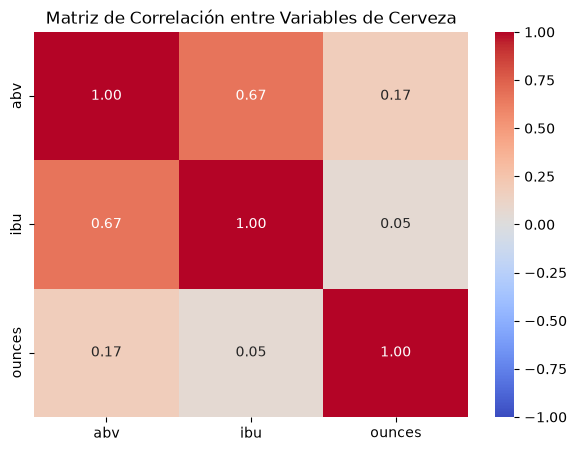

In [34]:
# Seleccionar solo las variables numéricas reales descartando identificadores
cols_interes = df_beer[['abv', 'ibu', 'ounces']]

# Calcular la matriz de correlación de Pearson
matriz_correlacion = cols_interes.corr()

# Dibujar el mapa de calor (Heatmap)
plt.figure(figsize=(7, 5))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlación entre Variables de Cerveza")
plt.show()

<span style="color:yellow">La función </span>`corr()`<span style="color:yellow"> analiza si dos variables se mueven juntas. Nos da un número entre -1 y 1: si es cercano a 1, significa que cuando una variable sube, la otra también sube de forma proporcional. Al aplicar </span>`sns.heatmap()`<span style="color:yellow"> convertimos esos números en colores (rojo para correlaciones altas y azul para bajas). En los resultados observaremos una relación lineal positiva destacada entre </span>`abv`<span style="color:yellow"> (alcohol) e </span>`ibu`<span style="color:yellow"> (amargor): las cervezas con mayor graduación alcohólica tienden a ser también sustancialmente más amargas.</span>

## Ejercicio 13
Representa el nivel de alcohol (columna `abv`) en un histograma. ¿Se trata de una distribución simétrica o asimétrica?

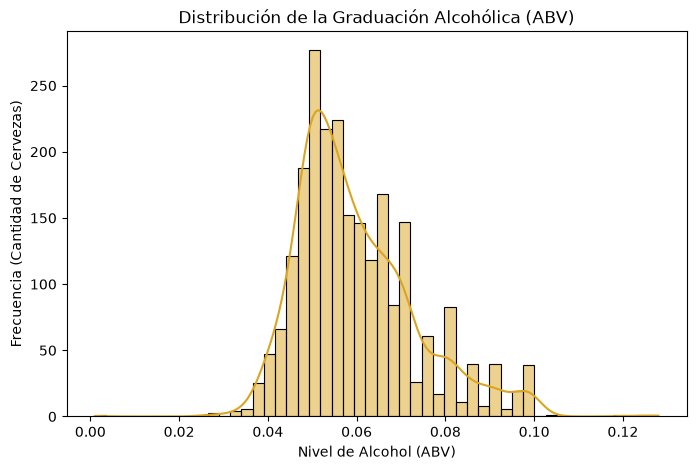

'Coeficiente de asimetría:'

np.float64(0.9584771340361382)

In [35]:
plt.figure(figsize=(8, 5))
# Dibujamos el histograma omitiendo valores nulos
sns.histplot(df_beer['abv'].dropna(), kde=True, color='goldenrod')
plt.title("Distribución de la Graduación Alcohólica (ABV)")
plt.xlabel("Nivel de Alcohol (ABV)")
plt.ylabel("Frecuencia (Cantidad de Cervezas)")
plt.show()

# Calculamos el coeficiente de asimetría (skewness)
display("Coeficiente de asimetría:", df_beer['abv'].skew())

<span style="color:yellow">Un histograma agrupa los datos en "cubos" o rangos numéricos y levanta barras según la cantidad de cervezas que caen en cada rango. La función </span>`sns.histplot()`<span style="color:yellow"> genera la gráfica y el parámetro </span>`kde=True`<span style="color:yellow"> dibuja una línea suave por encima. Al observar la gráfica vemos que la mayor concentración de cervezas está en graduaciones medias-bajas (0.04 a 0.06), pero la curva tiene una "cola" más alargada hacia la derecha (cervezas fuertes de 0.08 a 0.12). Por tanto, se trata de una distribución **asimétrica escorada a la derecha (asimetría positiva)**.</span>

## Ejercicio 14
Representa mediante un *boxplot* de `seaborn` la variable `abv`

ValueError: Invalid RGBA argument: 'amber'

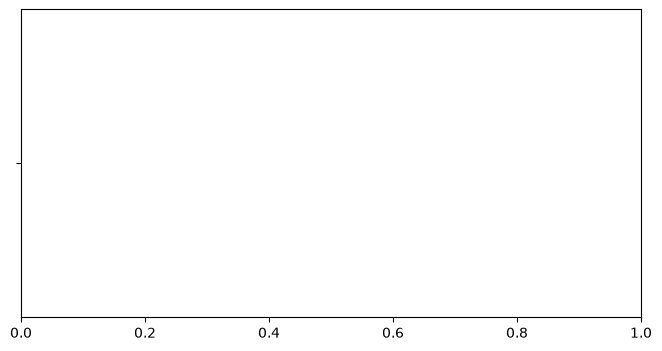

In [36]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_beer['abv'], color='amber')
plt.title("Diagrama de Caja (Boxplot) de ABV")
plt.xlabel("Graduación Alcohólica (ABV)")
plt.show()

<span style="color:yellow">La función </span>`sns.boxplot()`<span style="color:yellow"> resume la distribución de los datos en una sola figura geométrica:
1. La **caja central** representa el 50% de todas las cervezas del dataset (lo que va desde el primer cuartil 25% hasta el tercer cuartil 75%).
2. La **línea vertical dentro de la caja** marca la mediana exacta.
3. Las líneas que sobresalen a los lados (los **bigotes**) extienden el rango normal de los datos.
4. Los **puntos aislados** situados más allá del bigote derecho representan cervezas con un volumen de alcohol excepcionalmente alto (*outliers*).</span>

## Ejercicio 15
1. ¿Qué estilos son los que tienen en media más alcohol?
2. ¿Y los estilos que son en media más amargos?

In [ ]:
# Top 5 estilos con mayor media de alcohol
top_alcohol = df_beer.groupby('style')['abv'].mean().sort_values(ascending=False).head(5)

# Top 5 estilos con mayor media de amargor
top_amargor = df_beer.groupby('style')['ibu'].mean().sort_values(ascending=False).head(5)

display("--- Estilos con mayor graduación alcohólica en media ---")
display(top_alcohol)

display("\n--- Estilos más amargos en media ---")
display(top_amargor)

<span style="color:yellow">Para responder a estas preguntas combinamos tres comandos en cadena. Primero, </span>`groupby('style')`<span style="color:yellow"> separa mentalmente las cervezas en carpetas según su estilo. Segundo, seleccionamos la columna deseada (</span>`['abv']`<span style="color:yellow"> o </span>`['ibu']`<span style="color:yellow">) y le aplicamos </span>`mean()`<span style="color:yellow"> para calcular el promedio exacto de cada carpeta. Por último, </span>`sort_values(ascending=False)`<span style="color:yellow"> ordena la lista resultante de mayor a menor y </span>`head(5)`<span style="color:yellow"> nos muestra únicamente el podio de los 5 estilos ganadores.</span>

## Ejercicio 16
Carga el datasets de cervecerias `datasets_breweries.csv`

In [ ]:
df_breweries = pd.read_csv("datasets_breweries.csv")
df_breweries.head()

<span style="color:yellow">Cargamos el segundo archivo de datos usando nuevamente la función </span>`pd.read_csv()`<span style="color:yellow"> y asignándolo a una nueva variable independiente llamada </span>`df_breweries`<span style="color:yellow">. Al ejecutar </span>`df_breweries.head()`<span style="color:yellow"> confirmamos que este dataset contiene datos referentes a los productores: su nombre, ciudad y el estado de EEUU al que pertenecen.</span>

## Ejercicio 17
1. Renombra la columna `Unnamed: 0` como `brewery_id`
2. Renombra también la columna `name` por `brewery_name`. ¿Puedes hacer ambos apartados en una sola sentencia?

In [ ]:
# Renombrar ambas columnas en una sola instrucción pasándole un diccionario
df_breweries = df_breweries.rename(columns={
    'Unnamed: 0': 'brewery_id',
    'name': 'brewery_name'
})

df_breweries.head()

<span style="color:yellow">El método </span>`rename()`<span style="color:yellow"> nos permite cambiar el título de cualquier columna. Para modificar varias a la vez en una sola sentencia, le pasamos al parámetro </span>`columns=`<span style="color:yellow"> un diccionario escrito entre llaves </span>`{}`<span style="color:yellow">. En este diccionario ponemos el nombre original a la izquierda y el nuevo nombre deseado a la derecha, separados por dos puntos. Cambiamos </span>`Unnamed: 0`<span style="color:yellow"> por </span>`brewery_id`<span style="color:yellow"> (que servirá de conector) y </span>`name`<span style="color:yellow"> por </span>`brewery_name`<span style="color:yellow"> para no confundir el nombre de la fábrica con el nombre de la cerveza.</span>

## Ejercicio 18
Junta los dos datasets que tienes

In [ ]:
# Cruzamos ambas tablas por la columna clave 'brewery_id'
df_merged = pd.merge(df_beer, df_breweries, on='brewery_id', how='inner')
df_merged.head()

<span style="color:yellow">La función </span>`pd.merge()`<span style="color:yellow"> funciona igual que un **BUSCARV** en Excel o un **JOIN** en SQL. Toma la tabla de cervezas (</span>`df_beer`<span style="color:yellow">) y la de cervecerías (</span>`df_breweries`<span style="color:yellow">) y busca filas donde el valor de la columna </span>`brewery_id`<span style="color:yellow"> coincida exactamente en ambas partes. El argumento </span>`how='inner'`<span style="color:yellow"> asegura que solo conservemos las filas que encuentran su pareja en la otra tabla. La tabla resultante, </span>`df_merged`<span style="color:yellow">, contiene ahora la información completa: las características de la cerveza junto con los datos de la fábrica que la elaboró.</span>

## Ejercicio 19
1. ¿Cuántos estados diferentes hay?
2. ¿Y ciudades diferentes?
3. ¿Cuántas cervecerías hay?

In [ ]:
num_estados = df_merged['state'].nunique()
num_ciudades = df_merged['city'].nunique()
num_cervecerias = df_merged['brewery_id'].nunique()

display(f"Número de estados diferentes: {num_estados}")
display(f"Número de ciudades diferentes: {num_ciudades}")
display(f"Número de cervecerías diferentes: {num_cervecerias}")

<span style="color:yellow">Mientras que </span>`count()`<span style="color:yellow"> cuenta cuántas casillas rellenas hay en total, el método </span>`nunique()`<span style="color:yellow"> (que viene de *Number of Unique*) actúa como un filtro inteligente: examina la columna, elimina conceptualmente todos los duplicados y nos dice la cantidad exacta de elementos distintos que ha encontrado. Así descubrimos el número real de estados, ciudades y fabricantes sin contar dos veces la misma fábrica aunque venda 20 cervezas diferentes.</span>

## Ejercicio 20
Agrupa por estado y ciudad, la media, mediana y máximo nivel de alcohol

In [ ]:
# Agrupamos por estado y ciudad, y aplicamos múltiples funciones agregadas a 'abv'
resumen_alcohol_local = df_merged.groupby(['state', 'city'])['abv'].agg(['mean', 'median', 'max'])
resumen_alcohol_local.head(10)

<span style="color:yellow">El comando </span>`groupby(['state', 'city'])`<span style="color:yellow"> crea una estructura jerárquica: dentro de cada estado, crea subgrupos para cada ciudad disponible. A continuación, seleccionamos la variable </span>`['abv']`<span style="color:yellow"> y usamos el método </span>`agg()`<span style="color:yellow"> (de *aggregate*). La ventaja de </span>`agg()`<span style="color:yellow"> es que nos permite solicitar múltiples cálculos matemáticos a la vez pasando una lista con los nombres de las funciones deseadas: </span>`'mean'`<span style="color:yellow"> (media), </span>`'median'`<span style="color:yellow"> (mediana) y </span>`'max'`<span style="color:yellow"> (máximo).</span>

## Ejercicio 21
¿Cuáles son las cervezas más amargas que se consumen en Indiana, estado = `IN`?

In [ ]:
# 1. Filtrar los datos correspondientes al estado de Indiana (limpiando posibles espacios)
cervezas_indiana = df_merged[df_merged['state'].str.strip() == 'IN']

# 2. Ordenar descendentemente por amargor (IBU)
amargas_indiana = cervezas_indiana.sort_values(by='ibu', ascending=False)

# Mostrar las columnas más relevantes de los primeros resultados
amargas_indiana[['name', 'brewery_name', 'city', 'ibu']].head()

<span style="color:yellow">Primero creamos una condición de filtrado: </span>`df_merged['state'].str.strip() == 'IN'`<span style="color:yellow">. El fragmento </span>`.str.strip()`<span style="color:yellow"> elimina cualquier espacio oculto en el texto antes de comprobar si coincide con el código de estado 'IN'. Al envolver esa condición entre corchetes sobre la tabla principal, descartamos el resto del país. Finalmente, aplicamos </span>`sort_values(by='ibu', ascending=False)`<span style="color:yellow"> sobre la subtabla de Indiana para ordenar las cervezas desde la que tiene más IBU hasta la que menos.</span>

## Ejercicio 22
Obtén una tabla con los principales estadísticos del campo `ibu`,  a nivel ciudad

In [ ]:
stats_ibu_por_ciudad = df_merged.groupby('city')['ibu'].describe()
stats_ibu_por_ciudad.head(10)

<span style="color:yellow">Combinar dos comandos sencillos nos da un resultado enormemente potente. Al escribir </span>`groupby('city')['ibu']`<span style="color:yellow"> organizamos el amargor de todas las cervezas separándolas por la ciudad de su fábrica. Al añadir </span>`.describe()`<span style="color:yellow"> al final, Pandas calcula automáticamente la media, la desviación típica, el mínimo, el máximo y los tres cuartiles del amargor de forma independiente para cada una de las ciudades del dataset.</span>

## Ejercicio 23
Consigue en un DataFrame de todas las cervezas en cuyas cervecerías al menos haya una cerveza con un `abv` mínimo 0.07.

In [ ]:
# Paso 1: Obtener los identificadores únicos de las cervecerías con al menos una cerveza de abv >= 0.07
cervecerias_fuertes = df_merged[df_merged['abv'] >= 0.07]['brewery_id'].unique()

# Paso 2: Filtrar la tabla combinada original conservando todas las cervezas de esas cervecerías
df_resultado_cervecerias = df_merged[df_merged['brewery_id'].isin(cervecerias_fuertes)]

df_resultado_cervecerias.head()

<span style="color:yellow">Para no caer en la trampa dividimos el problema en dos pasos lógicos:
1. En el primer paso aislamos las cervezas con más de 7% de alcohol (</span>`abv >= 0.07`<span style="color:yellow">) y le pedimos a Pandas con </span>`.unique()`<span style="color:yellow"> que nos dé la lista de los IDs de las fábricas que producen esas cervezas.
2. En el segundo paso utilizamos el método </span>`.isin(cervecerias_fuertes)`<span style="color:yellow">. Esto actúa como un passe-partout: busca en la tabla original y rescata todas las cervezas cuyos fabricantes estén en nuestra lista de "cervecerías potentes", independientemente de la graduación alcohólica individual de cada una de ellas.</span>

## Ejercicio 24
Teniendo en cuenta la media de amargor de todas las cervezas, obtén una tabla con las cervezas cuyos estados tengan una media de amargor en cerveza por encima de la media

In [ ]:
# 1. Calcular la media global de amargor de todas las cervezas
media_global_ibu = df_merged['ibu'].mean()

# 2. Calcular la media de amargor asignada a cada estado usando transform()
media_estado_ibu = df_merged.groupby('state')['ibu'].transform('mean')

# 3. Filtrar las cervezas de los estados que superan la media de amargor nacional
df_estados_mas_amargos = df_merged[media_estado_ibu > media_global_ibu]

display(f"Media global de amargor (IBU): {media_global_ibu:.2f}")
display("Muestra del DataFrame resultante:")
df_estados_mas_amargos[['name', 'state', 'ibu']].head()

<span style="color:yellow">Este ejercicio requiere una herramienta avanzada de Pandas llamada </span>`transform('mean')`<span style="color:yellow">.
1. Primero calculamos </span>`media_global_ibu`<span style="color:yellow"> obteniendo una única cifra promedio nacional de amargor para todas las cervezas.
2. Usar </span>`groupby('state')['ibu'].transform('mean')`<span style="color:yellow"> es la clave: calcula la media de amargor de cada estado, pero en lugar de resumir la tabla, "pega" esa media regional en cada una de las filas correspondientes de la tabla original.
3. Finalmente, comparamos fila por fila si la media de amargor del estado donde se hizo esa cerveza es mayor que la media de todo el dataset (</span>`media_estado_ibu > media_global_ibu`<span style="color:yellow">). Conservamos únicamente las cervezas fabricadas en los estados con tradición de cervezas más amargas que la media nacional.</span>